In [1]:
#!/usr/bin/env python3
import os, sys, time, logging
import numpy as np
import pandas as pd
import argparse
import matplotlib.pyplot as plt

# Import project modules
if "/mnt/research/ascsn/aaron-philip/barrier-extraction/src" not in sys.path:
    sys.path.append("/mnt/research/ascsn/aaron-philip/barrier-extraction/src")
from train import ChangePointKernel, init_E0, run_wong_trial, fit_wong_with_restarts, make_x_pred, draw_sigma_samples,percentile_bands,barrier_from_sigma_samples,fit_wong
from utils import load_packed_hdf5 # updated import
from wong import sigma

In [3]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic

def train_gp_bad(
    E, Sigma, Sigma_err,
    n_restarts=2, n_samples=200, random_state=None
):
    """
    GP regression on (E, Sigma) with simple RBF kernel and heteroscedastic noise via alpha=Sigma_err^2.
    Returns arrays for HDF5 writing: x_pred, y_mean, y_samples, and barrier-space summaries.
    """
    # --- defensives & shapes ---
    E = np.asarray(E, float).reshape(-1)
    Sigma = np.asarray(Sigma, float).reshape(-1)
    Sigma_err = np.asarray(Sigma_err, float).reshape(-1)

    # ensure sorted by energy (GP prefers monotonic X for some diagnostics)
    order = np.argsort(E)
    E, Sigma, Sigma_err = E[order], Sigma[order], Sigma_err[order]

    # --- kernel and GP ---
    # length scale bounds based on grid spacing; robust to irregular grids
    if len(E) > 1:
        dE = np.diff(E)
        ell_min = max(1e-3, np.min(np.abs(dE)))
        ell_max = max(5.0, 10.0 * np.median(np.abs(dE)))
    else:
        ell_min, ell_max = 1e-3, 10.0
    kernel = ConstantKernel()*RBF(length_scale=1.0, length_scale_bounds=(ell_min, ell_max))

    gp = GaussianProcessRegressor(
        kernel=kernel,
        alpha=np.maximum(Sigma_err, 1e-12) ** 2,   # heteroscedastic obs noise
        n_restarts_optimizer=int(n_restarts),
        normalize_y=False,
        random_state=random_state,
    )

    # --- fit ---
    gp.fit(E.reshape(-1, 1), Sigma)
    kernel_opt = str(gp.kernel_)
    lml = float(getattr(gp, "log_marginal_likelihood_value_", np.nan))

    # --- prediction grid (match Wong plotting style) ---
    x_pred = np.arange(max(0.0, E.min() - 5.0), E.max() + 5.0, 0.2).astype(float)
    Xp = x_pred.reshape(-1, 1)

    # posterior mean and samples
    y_mean, _ = gp.predict(Xp, return_std=True)
    y_samples = gp.sample_y(Xp, n_samples=n_samples, random_state=random_state).T  # (S, M)

    return gp, ell_min, ell_max

def train_gp_good(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, fixed_length=None, noise=None, log=False):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        if fixed_length is not None:
            # FIXED correlation length
            k_rbf = ConstantKernel(constant_value_bounds=(1e-05, 10000000.0)) * RBF(
                length_scale=fixed_length,
                length_scale_bounds="fixed"
            )
        else:
            # Optimizable correlation length
            k_rbf = ConstantKernel(constant_value_bounds=(1e-05, 10000000.0)) * RBF(
                length_scale=1.0,
                length_scale_bounds=(lbound, ubound)
            )
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    if log: 
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha= sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))

    return gp, lbound, ubound


from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel, WhiteKernel, RationalQuadratic
)

def train_gp_rq(
    E_train,
    sigma_mu_train,
    sigma_var_train,
    n_restarts=20,
    kernel=None,
    fixed_length=None,
    noise=None,
    log=False
):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise,
    using a Rational Quadratic kernel.

    Parameters
    ----------
    E_train : array-like (N,)
    sigma_mu_train : array-like (N,)
    sigma_var_train : array-like (N,)
        Noise variances at training points.
    """

    # ---- Sorting for length-scale bounds (not used for RQ but kept for consistency) ----
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0, 10.0

    # signal variance (not used directly)
    var_y0 = np.var(sigma_mu_train)
    print("Var(y) =", var_y0)

    # ------------------------------------------------
    # Build Rational Quadratic kernel
    # ------------------------------------------------
    if kernel is None:
        if fixed_length is not None:
            # RQ with FIXED length scale
            k_rq = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(
                length_scale=fixed_length,
                length_scale_bounds="fixed",
                alpha=1.0,             # shape parameter
                alpha_bounds=(1e-12, 1e2)
            )
        else:
            # RQ with optimized length scale
            k_rq = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(
                length_scale=1.0,
                length_scale_bounds=(lbound, ubound),
                alpha=1.0,
                alpha_bounds=(1e-12, 1e2)
            )

        kernel = k_rq

        if noise:
            kernel += WhiteKernel(noise_level=1e-5, noise_level_bounds=(1e-9, 1e-3))

    # ------------------------------------------------
    # Build GP model
    # ------------------------------------------------
    if log:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts,
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1),
               np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts,
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1),
               np.asarray(sigma_mu_train))

    return gp, lbound, ubound


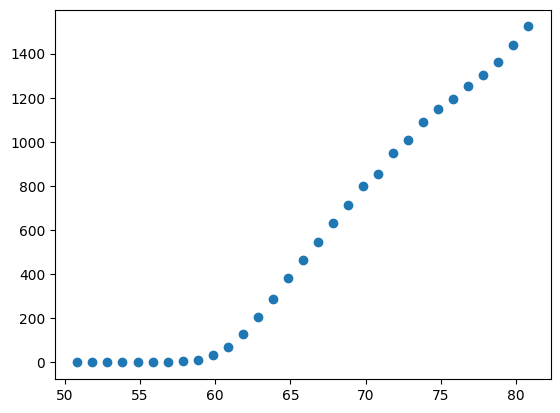

In [5]:
i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/res_1.00MeV_noise0.01.h5"
ds = load_packed_hdf5(data_path)
E_train, Sigma_train, Sigma_err_train, params_i = ds["get_i"](i) # note: uses init_E0 inside
E_pred = make_x_pred(E_train)
plt.plot(E_train, Sigma_train, "o")

60.83164205890171 50.82984276377401 80.82984276377401
theta dim: (8,)
bounds dim: (8, 2)
Var(y) = 279687.5009336152


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 33 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


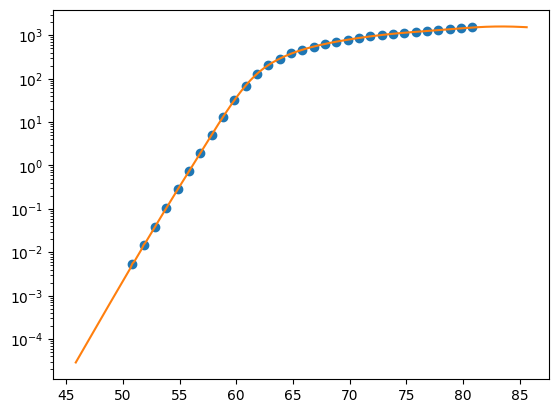

In [6]:
from sklearn.gaussian_process.kernels import ConstantKernel, RationalQuadratic, WhiteKernel

# two regimes
k_left  = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(length_scale=2.0, alpha=1.0)
k_right = ConstantKernel(1.0, (1e-5, 1e5)) * RationalQuadratic(length_scale=8.0, alpha=1.0)

# choose bounds for changepoint location based on your E range
Emin, Emax = float(np.min(E_train)), float(np.max(E_train))
p0 = init_E0(E_train, Sigma_train)
popt, pcov, chi2= fit_wong_with_restarts(E_train, Sigma_train, Sigma_err_train, n_restarts=5)
E0 = popt[0]
print(E0, Emin, Emax)
cp = ChangePointKernel(
    k1=k_right,
    k2=k_left,
    location=E0,
    width=2.0,
    location_bounds=(Emin, Emax),
    width_bounds=(1e-2, 50.0),
)

# optionally add extra white noise term (in addition to your heteroscedastic alpha)
#cp += WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-12, 1e-3))
print("theta dim:", cp.theta.shape)
print("bounds dim:", cp.bounds.shape)

#gp, lmin, lmax = train_gp_rq(E_train, np.log(Sigma_train) - np.log(sigma(E_train, *popt)), Sigma_err_train**2, n_restarts=20, kernel=cp)
gp, lmin, lmax = train_gp_rq(E_train, Sigma_train, Sigma_err_train**2, n_restarts=20, kernel=cp)

plt.plot(E_train, Sigma_train, "o")
#plt.plot(E_pred, np.exp(np.log(sigma(E_pred, *popt)) + gp.predict(E_pred.reshape(-1, 1))))
plt.plot(E_pred, gp.predict(E_pred.reshape(-1, 1)))
plt.yscale('log')
plt.show()

#plt.plot(E_pred, gp.predict(E_pred.reshape(-1, 1)) )


Var(y) = 347946.47338067327


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


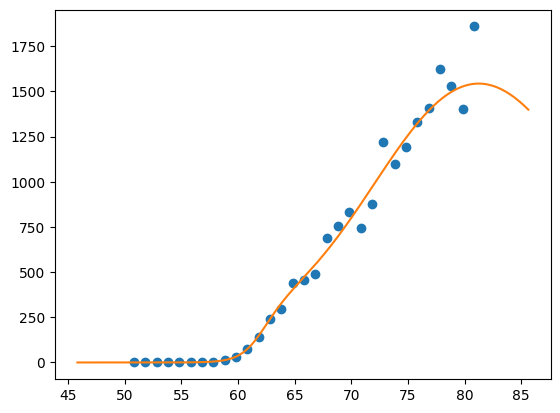

/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:526: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  y_samples = rng.multivariate_normal(y_mean, y_cov, n_samples).T


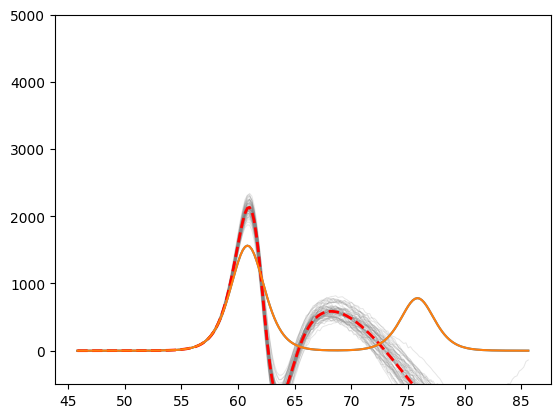

In [33]:
popt1 = popt + [15, 0, 0]
sigma1 = sigma(E_pred, *popt) + 0.5*sigma(E_pred, *popt1)
idx = np.searchsorted(E_pred, E_train)
sigma1_train = sigma1[idx] + np.random.normal(0.0, Sigma_err_train)
E_train1 = E_train

gp, lmin, lmax = train_gp_rq(E_train1, sigma1_train, Sigma_err_train**2, n_restarts=20, kernel=cp)


plt.plot(E_train1, sigma1_train, "o")
plt.plot(E_pred, gp.predict(E_pred.reshape(-1,1)))
plt.show()


D_true = barrier_from_sigma_samples(E_pred, sigma1.reshape(1,-1))[0]


#y_samples = np.exp(gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T +  np.log(sigma(E_pred, *popt)))
#y_mean = np.exp(gp.predict(E_pred.reshape(-1,1)) +  np.log(sigma(E_pred, *popt)))

y_samples = gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T
y_mean = gp.predict(E_pred.reshape(-1,1))

D_samples = barrier_from_sigma_samples(E_pred, y_samples)
D_mean = barrier_from_sigma_samples(E_pred, y_mean.reshape(1,-1))[0]

plt.plot(E_pred, D_true)
for D in D_samples:
    plt.plot(E_pred, D, color="gray", alpha=0.20, lw=0.7)

plt.plot(E_pred, D_mean, "r--", lw=2,
        label=f"Mean D(E)")
plt.ylim(-500, 5000)

plt.plot(E_pred, D_true)


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:526: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  y_samples = rng.multivariate_normal(y_mean, y_cov, n_samples).T


(-500.0, 5000.0)

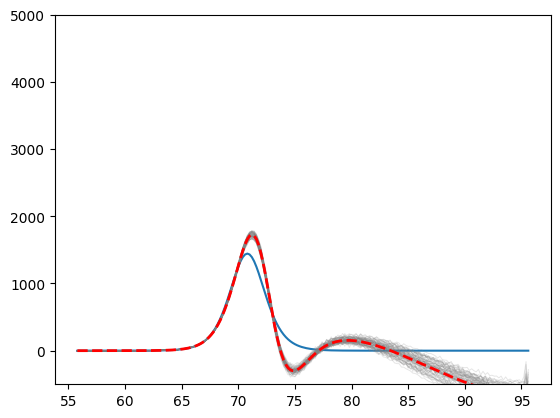

In [33]:
sigma_true = sigma(E_pred, *params_i)
D_true = barrier_from_sigma_samples(E_pred, sigma_true.reshape(1,-1))[0]

#y_samples = np.exp(gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T +  np.log(sigma(E_pred, *popt)))
#y_mean = np.exp(gp.predict(E_pred.reshape(-1,1)) +  np.log(sigma(E_pred, *popt)))

y_samples = gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T
y_mean = gp.predict(E_pred.reshape(-1,1))

D_samples = barrier_from_sigma_samples(E_pred, y_samples)
D_mean = barrier_from_sigma_samples(E_pred, y_mean.reshape(1,-1))[0]

plt.plot(E_pred, D_true)
for D in D_samples:
    plt.plot(E_pred, D, color="gray", alpha=0.20, lw=0.7)

plt.plot(E_pred, D_mean, "r--", lw=2,
        label=f"Mean D(E)")
plt.ylim(-500, 5000)



[77.25473133 10.6833096   6.33971773]
Var(y) = 69226.11643485342
Correlation length bounds: 0.0010000000000047748 10.0


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


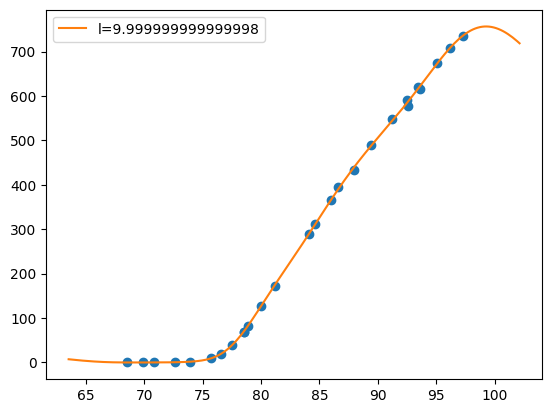

In [6]:
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.75_spacing1.0.h5"
ds = load_packed_hdf5(data_path)
E, Sigma, Sigma_err, params_i = ds["get_i"](i) # note: uses init_E0 inside
print(params_i)
E0_true, R0_true, hw_true = params_i

E = np.asarray(E, float).reshape(-1)
Sigma = np.asarray(Sigma, float).reshape(-1)
Sigma_err = np.asarray(Sigma_err, float).reshape(-1)

# ensure sorted by energy (GP prefers monotonic X for some diagnostics)
order = np.argsort(E)
E, Sigma, Sigma_err = E[order], Sigma[order], Sigma_err[order]

gp, lmin, lmax  = train_gp_rq(E, Sigma, Sigma_err**2, n_restarts=20)
plt.plot(E, Sigma, 'o')  # training data
E_pred = make_x_pred(E)
#E_pred = np.linspace(min(E)-40, max(E)+100, 200)
print("Correlation length bounds:", lmin, lmax)
plt.plot(E_pred, gp.predict(E_pred.reshape(-1, 1)), label=f"l={gp.kernel_.k2.length_scale}")

plt.legend()  # warm-up predict

### Varying Correlation Lengths for RBF

5.298317366548036

=== Correlation length ℓ = 0.01 ===
117512.02955270227
401**2 * RBF(length_scale=6.12)
  → trained constant: 160847.86696773642
  → trained ℓ: 6.116803009837493
(200,) (60, 200)


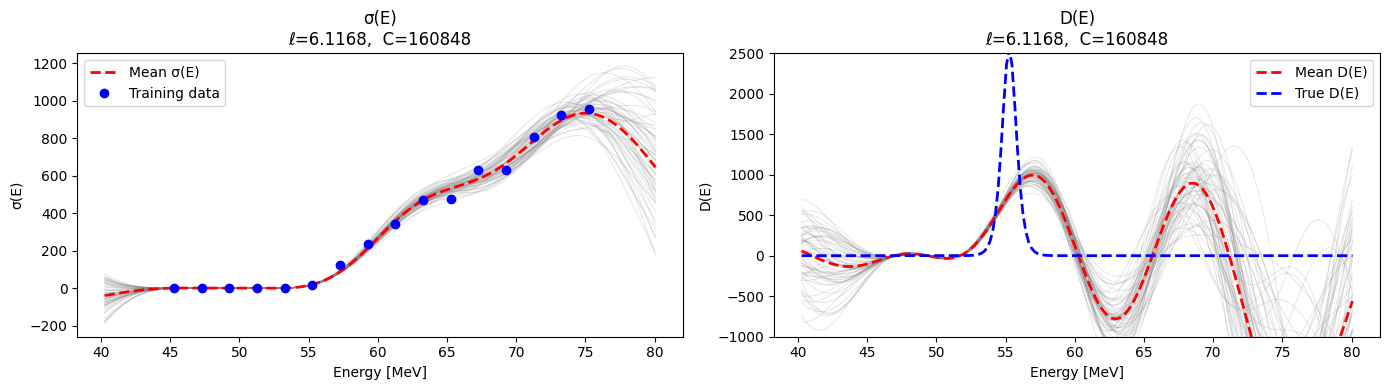


=== Correlation length ℓ = 0.06309573444801933 ===
117512.02955270227
481**2 * RBF(length_scale=0.0631)
  → trained constant: 230883.4277703128
  → trained ℓ: 0.06309573444801933
(200,) (60, 200)


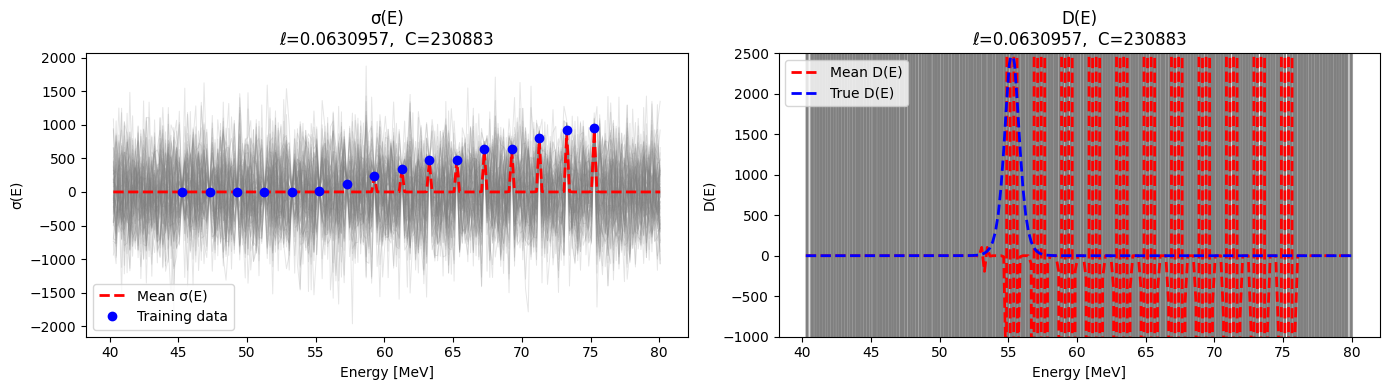


=== Correlation length ℓ = 0.3981071705534973 ===
117512.02955270227
481**2 * RBF(length_scale=0.398)
  → trained constant: 230882.10838408963
  → trained ℓ: 0.3981071705534973
(200,) (60, 200)


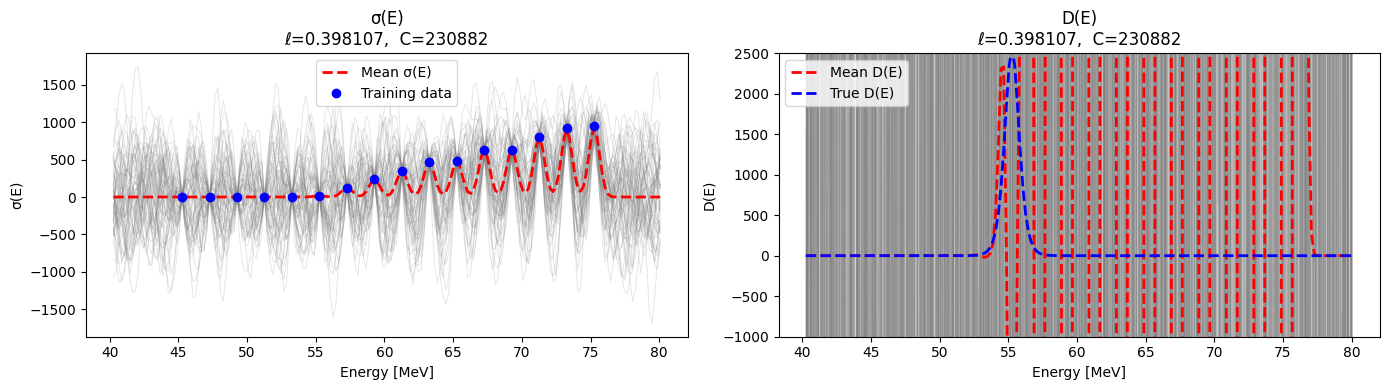


=== Correlation length ℓ = 2.511886431509582 ===
117512.02955270227
323**2 * RBF(length_scale=2.51)
  → trained constant: 104571.70638081558
  → trained ℓ: 2.511886431509582
(200,) (60, 200)


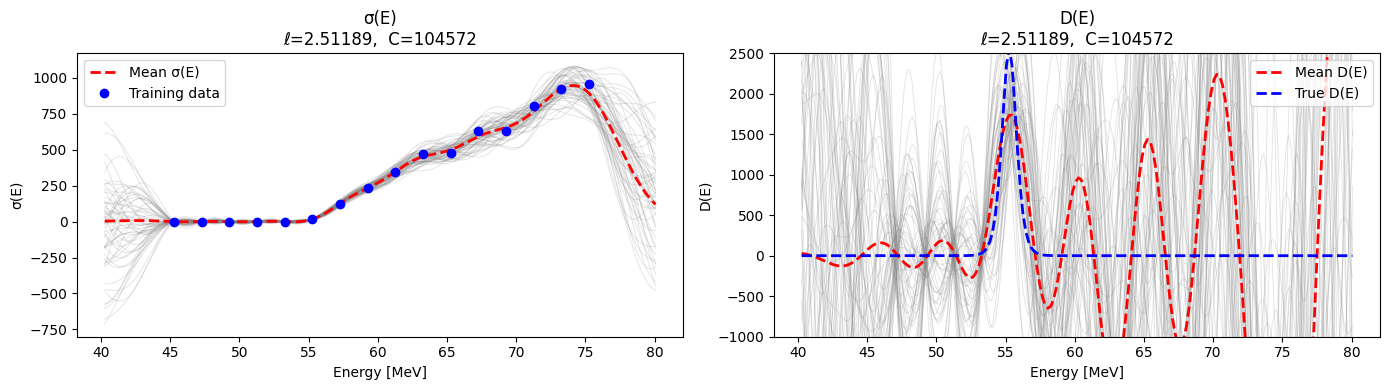


=== Correlation length ℓ = 15.848931924611142 ===
117512.02955270227
3.16e+03**2 * RBF(length_scale=15.8)
  → trained constant: 10000000.000000006
  → trained ℓ: 15.848931924611142


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:526: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  y_samples = rng.multivariate_normal(y_mean, y_cov, n_samples).T


(200,) (60, 200)


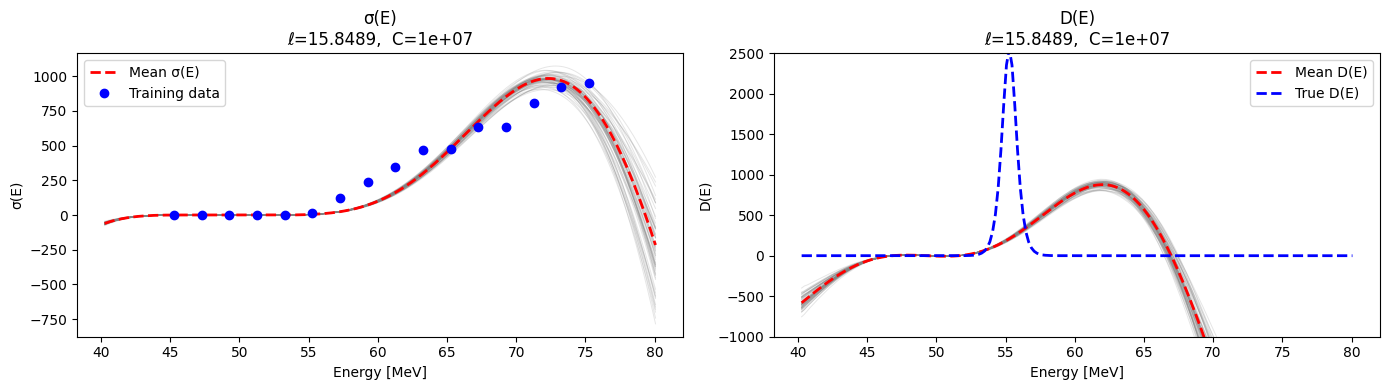


=== Correlation length ℓ = 100.0 ===
117512.02955270227


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


5.9**2 * RBF(length_scale=100)
  → trained constant: 34.77810293468029
  → trained ℓ: 100.0
(200,) (60, 200)


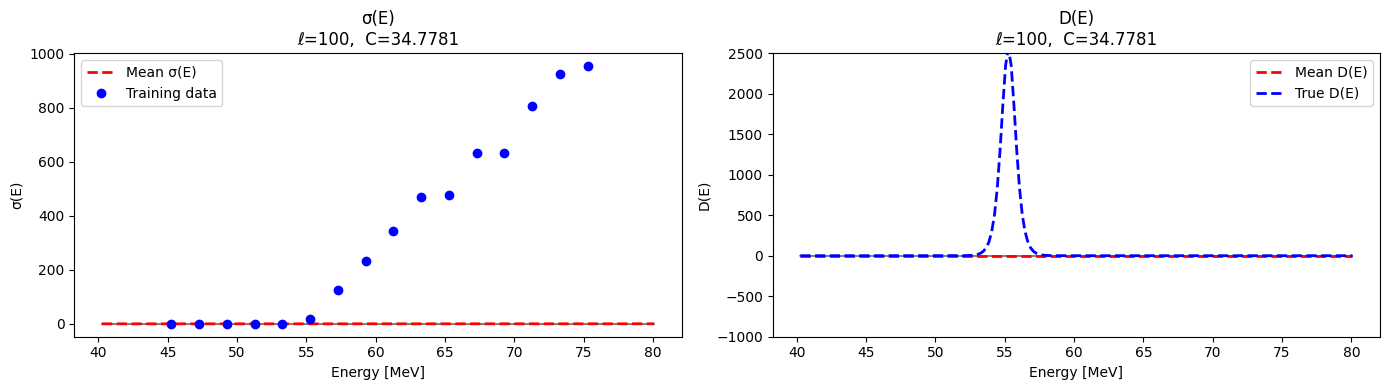

In [7]:
i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/res_2.00MeV_noise0.1.h5"
ds = load_packed_hdf5(data_path)
E_train, Sigma_train, Sigma_err_train, params_i = ds["get_i"](i) # note: uses init_E0 inside
E_pred = make_x_pred(E_train)

print(np.log(200.0))
lengths = np.logspace(np.log10(1e-2),np.log10(1e2), 6)   # correlation lengths

first = True
for L in lengths:
    print(f"\n=== Correlation length ℓ = {L} ===")

    # -------------------------
    # Train GP with fixed ℓ
    # -------------------------
    if first:
        gp, _, _ = train_gp_good(
            E_train,
            Sigma_train,
            Sigma_err_train**2,
            n_restarts=5,
            noise=False,
            log=False
        )
        first = False
    else:
        gp, _, _ = train_gp_good(
            E_train,
            Sigma_train,
            Sigma_err_train**2,
            n_restarts=20,
            fixed_length=L,
            noise=False,
            log=False
        )

    # Extract trained hyperparameters
    print(gp.kernel_)
    const_val = gp.kernel_.k1.constant_value
    ell_val   = gp.kernel_.k2.length_scale

    print("  → trained constant:", const_val)
    print("  → trained ℓ:", ell_val)

    # -------------------------
    # Predict mean + samples
    # -------------------------
    y_mean = gp.predict(E_pred.reshape(-1,1))
    #y_mean = np.exp(y_mean)
    y_samples = gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T

    print(y_mean.shape, y_samples.shape)

    # -------------------------
    # Compute barriers
    # -------------------------
    D_samples = barrier_from_sigma_samples(E_pred, y_samples)
    D_mean = barrier_from_sigma_samples(E_pred, y_mean.reshape(1,-1))[0]

    sigma_true = sigma(E_pred, *params_i)
    D_true = barrier_from_sigma_samples(E_pred, sigma_true.reshape(1,-1))[0]

    # -------------------------
    # Two-panel figure
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # ================
    # Panel 1: σ(E)
    # ================
    ax = axes[0]

    for y in y_samples:
        ax.plot(E_pred, y, color="gray", alpha=0.20, lw=0.7)

    ax.plot(E_pred, y_mean, "r--", lw=2,
            label=f"Mean σ(E)")

    ax.plot(E_train, Sigma_train, "bo", label="Training data")

    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("σ(E)")
    ax.set_title(
        f"σ(E)\nℓ={ell_val:g},  C={const_val:g}"
    )
    ax.legend()

    # ================
    # Panel 2: D(E)
    # ================
    ax = axes[1]

    for D in D_samples:
        ax.plot(E_pred, D, color="gray", alpha=0.20, lw=0.7)

    ax.plot(E_pred, D_mean, "r--", lw=2,
            label=f"Mean D(E)")

    ax.plot(E_pred, D_true, "b--", lw=2, label="True D(E)")

    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("D(E)")
    ax.set_ylim(-1000, 2500)
    ax.set_title(
        f"D(E)\nℓ={ell_val:g},  C={const_val:g}"
    )
    ax.legend()

    plt.tight_layout()
    plt.show()

### Varying Correlation Lengths for Rational Quadratic Kernel

5.298317366548036

=== Correlation length ℓ = 49.99999999999999 ===
Var(y) = 116761.52310588564
14.5**2 * RationalQuadratic(alpha=0.144, length_scale=10)
  → trained constant: 209.53040133348026
  → trained ℓ: 9.999999999999998


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


(195,) (60, 195)


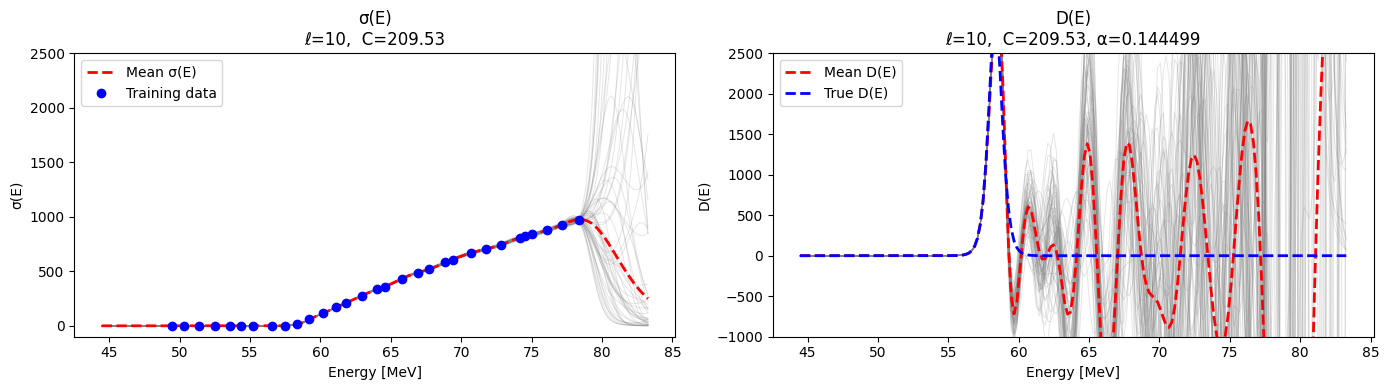


=== Correlation length ℓ = 57.434917749851756 ===
Var(y) = 116761.52310588564


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 16 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


79.6**2 * RationalQuadratic(alpha=0.00408, length_scale=57.4)
  → trained constant: 6342.558940792479
  → trained ℓ: 57.434917749851756
(195,) (60, 195)


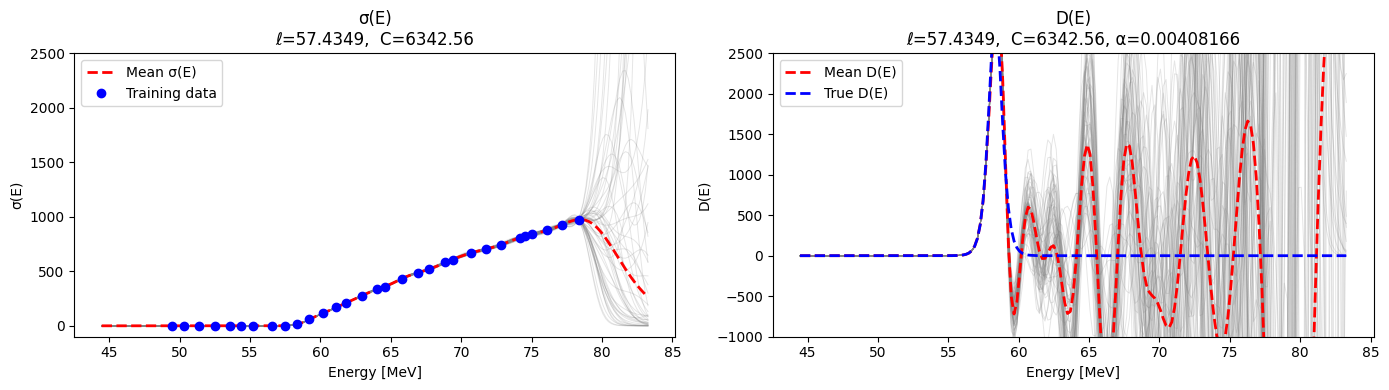


=== Correlation length ℓ = 65.9753955386447 ===
Var(y) = 116761.52310588564


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 19 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 16 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to 

91.5**2 * RationalQuadratic(alpha=0.00309, length_scale=66)
  → trained constant: 8363.798893794588
  → trained ℓ: 65.9753955386447
(195,) (60, 195)


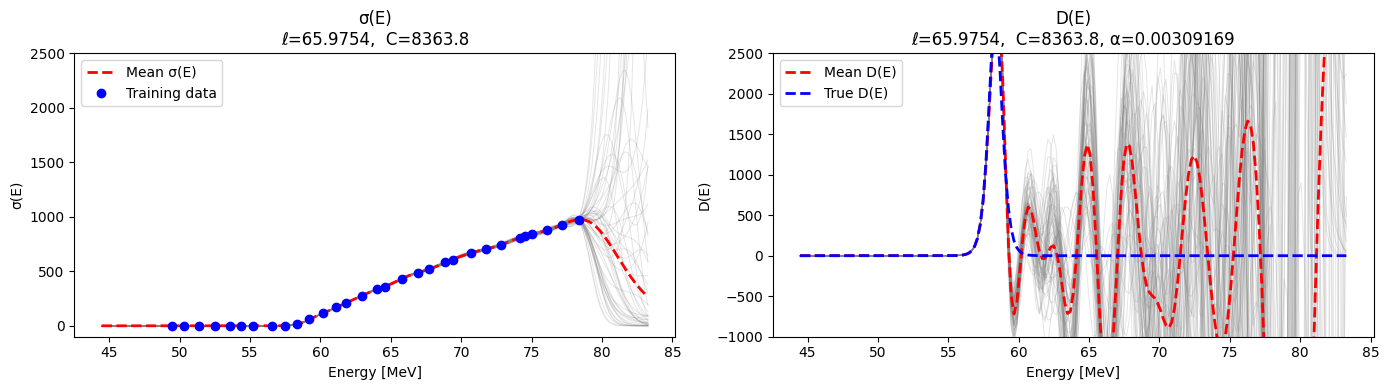


=== Correlation length ℓ = 75.7858283255199 ===
Var(y) = 116761.52310588564


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 11 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to 

105**2 * RationalQuadratic(alpha=0.00234, length_scale=75.8)
  → trained constant: 11030.785871449456
  → trained ℓ: 75.7858283255199
(195,) (60, 195)


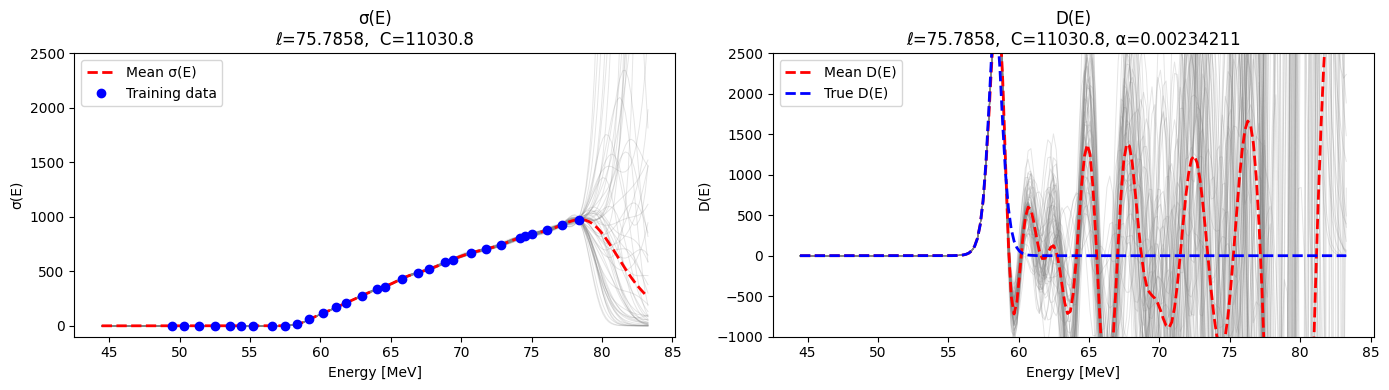


=== Correlation length ℓ = 87.05505632961238 ===
Var(y) = 116761.52310588564


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 20 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 2 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to sc

121**2 * RationalQuadratic(alpha=0.00177, length_scale=87.1)
  → trained constant: 14550.628590690463
  → trained ℓ: 87.05505632961238
(195,) (60, 195)


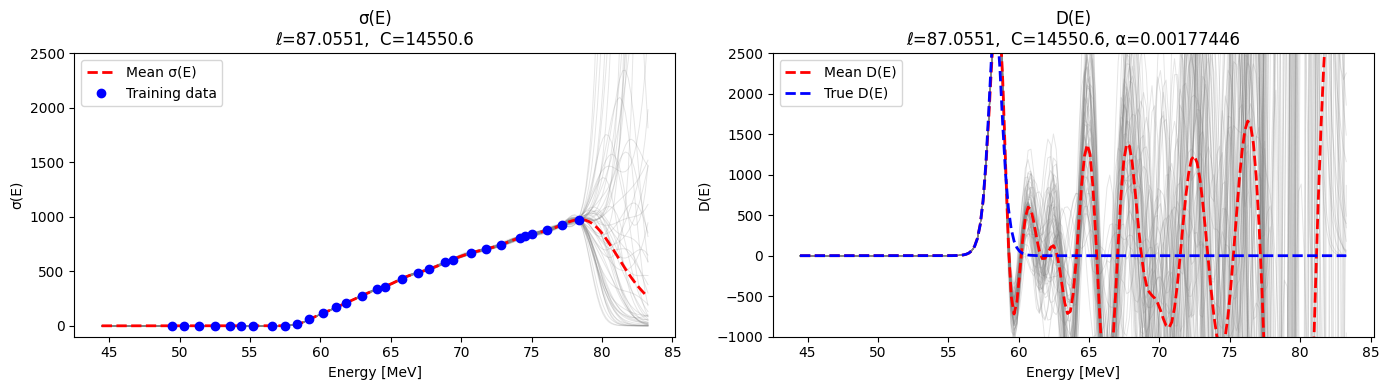


=== Correlation length ℓ = 100.0 ===
Var(y) = 116761.52310588564


/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 19 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/mnt/home/philipaa/envs/autobnn-reproduce2/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH

You might also want to 

139**2 * RationalQuadratic(alpha=0.00134, length_scale=100)
  → trained constant: 19193.60350768841
  → trained ℓ: 100.0
(195,) (60, 195)


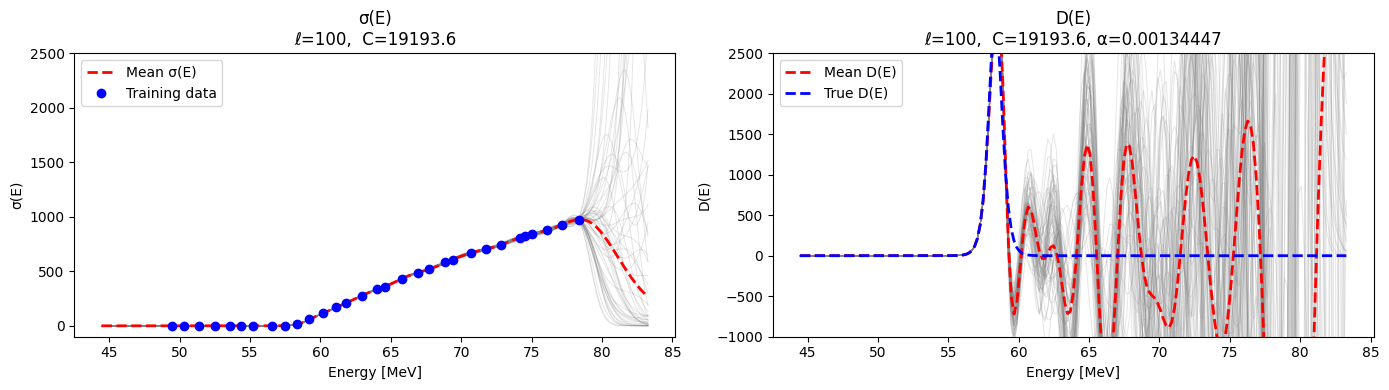

In [8]:
i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.25_spacing1.0.h5"#res_2.00MeV_noise0.1.h5" 
#"cv0.25_spacing1.0.h5"
#
ds = load_packed_hdf5(data_path)
E_train, Sigma_train, Sigma_err_train, params_i = ds["get_i"](i) # note: uses init_E0 inside
E_pred = make_x_pred(E_train)

print(np.log(200.0))
lengths = np.logspace(np.log10(50.0),np.log10(100.0), 6)   # correlation lengths

first = True
for L in lengths:
    print(f"\n=== Correlation length ℓ = {L} ===")

    # -------------------------
    # Train GP with fixed ℓ
    # -------------------------
    if first:
        gp, _, _ = train_gp_rq(
            E_train,
            Sigma_train, #(Sigma_train-np.mean(Sigma_train)),
            Sigma_err_train**2,
            n_restarts=5,
            noise=False,
            log=True
        )
        first = False
    else:
        gp, _, _ = train_gp_rq(
            E_train,
            Sigma_train,
            Sigma_err_train**2,
            n_restarts=20,
            fixed_length=L,
            noise=False,
            log=True
        )

    # Extract trained hyperparameters
    print(gp.kernel_)
    const_val = gp.kernel_.k1.constant_value
    ell_val   = gp.kernel_.k2.length_scale
    alpha_val = gp.kernel_.k2.alpha

    print("  → trained constant:", const_val)
    print("  → trained ℓ:", ell_val)

    # -------------------------
    # Predict mean + samples
    # -------------------------
    y_mean = np.exp(gp.predict(E_pred.reshape(-1,1))) #+ np.mean(Sigma_train)
    #y_mean = np.exp(y_mean)
    y_samples = np.exp(gp.sample_y(E_pred.reshape(-1,1), n_samples=60).T)   #+ np.mean(Sigma_train)

    print(y_mean.shape, y_samples.shape)

    # -------------------------
    # Compute barriers
    # -------------------------
    D_samples = barrier_from_sigma_samples(E_pred, y_samples)
    D_mean = barrier_from_sigma_samples(E_pred, y_mean.reshape(1,-1))[0]

    sigma_true = sigma(E_pred, *params_i)
    D_true = barrier_from_sigma_samples(E_pred, sigma_true.reshape(1,-1))[0]

    # -------------------------
    # Two-panel figure
    # -------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # ================
    # Panel 1: σ(E)
    # ================
    ax = axes[0]

    for y in y_samples:
        ax.plot(E_pred, y, color="gray", alpha=0.20, lw=0.7)

    ax.plot(E_pred, y_mean, "r--", lw=2,
            label=f"Mean σ(E)")

    ax.plot(E_train, Sigma_train, "bo", label="Training data")
    ax.set_ylim(-100, 2500)
    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("σ(E)")
    ax.set_title(
        f"σ(E)\nℓ={ell_val:g},  C={const_val:g}"
    )
    ax.legend()

    # ================
    # Panel 2: D(E)
    # ================
    ax = axes[1]

    for D in D_samples:
        ax.plot(E_pred, D, color="gray", alpha=0.20, lw=0.7)

    ax.plot(E_pred, D_mean, "r--", lw=2,
            label=f"Mean D(E)")

    ax.plot(E_pred, D_true, "b--", lw=2, label="True D(E)")

    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("D(E)")
    ax.set_ylim(-1000, 2500)
    ax.set_title(
        f"D(E)\nℓ={ell_val:g},  C={const_val:g}, α={alpha_val:g}"
    )
    ax.legend()

    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np

def rbf_matrix(x, C, l):
    """
    Construct an NxN matrix with entries:
        K_ij = C * exp( - (x_i - x_j)^2 / l^2 )

    Parameters
    ----------
    x : array-like, shape (N,)
        Input points.
    C : float
        Amplitude.
    l : float
        Length scale.

    Returns
    -------
    K : ndarray, shape (N, N)
        RBF kernel matrix.
    """
    mat = np.zeros((len(x), len(x)))
    for i in range(len(x)):
        for j in range(len(x)):
            mat[i,j] = C * np.exp( - (x[i] - x[j])**2 / l**2 )  
   # x = np.asarray(x)
   # # pairwise squared differences
    #diff = x[:, None] - x[None, :]

    return mat #C * np.exp(-(diff**2) / (l**2))


for a in np.linspace(0,1, 10):#np.logspace(np.log10(1e-6),np.log10(2.0), 6):
    corr = rbf_matrix(E_train[::2], 1.0, 5.0)
    err = a*np.diag(Sigma_err_train[::2]**2)

    mat = corr + err
    im = plt.imshow(mat)
    plt.colorbar(im)
    plt.show()

    plt.imshow(mat - (mat).T)
    plt.colorbar(im)
    plt.show()

    inv = np.linalg.inv(mat)
    im = plt.imshow(inv)
    plt.title(f"a={a}   ")
    plt.show()

    plt.imshow(inv - inv.T)
    plt.colorbar(im)
    plt.show()

    plt.imshow(np.matmul(inv, mat))
    plt.title("Product of inverse and original")
    plt.colorbar(im)
    plt.show()
    print(np.linalg.cond(mat))

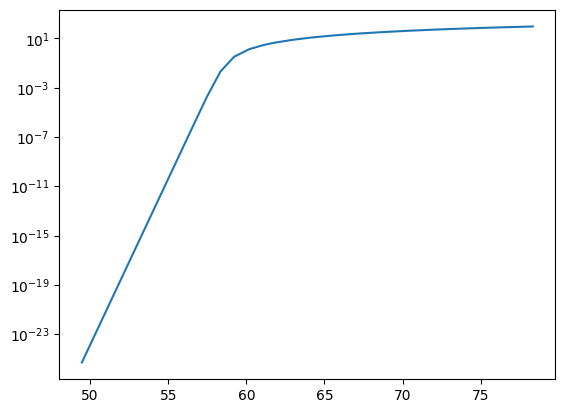

In [10]:
plt.plot(E_train, (Sigma_err_train)**2)  
plt.yscale("log")

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

i = 623
data_path = "/mnt/home/philipaa/scratch/barrier-paper-datasets/cv0.75_spacing1.0.h5"
ds = load_packed_hdf5(data_path)
E_train, Sigma_train, Sigma_err_train, params_i = ds["get_i"](i) # note: uses init_E0 inside
E_pred = make_x_pred(E_train)



def gp_pointwise_contributions(gp, X_star):
    """
    contributions[i, j] = c_i(x_j) = k(x_j, x_i)*alpha_i
    mu[j] = sum_i c_i(x_j)
    """
    X = gp.X_train_
    alpha = gp.alpha_
    kernel = gp.kernel_

    K_star = kernel(X_star, X)   # shape (M, N)
    contributions = K_star * alpha[np.newaxis, :]
    mu = contributions.sum(axis=1)

    return contributions, mu


# ------------------------------
# Train GP + compute contributions
# ------------------------------
gp, _, _ = train_gp_good(
    E_train,
    Sigma_train,
    Sigma_err_train**2,
    n_restarts=20,
    noise=False,
    log=False
)

X_star = E_pred.reshape(-1, 1)
contrib, mu = gp_pointwise_contributions(gp, X_star)
#contrib = np.exp(contrib)
#mu = np.exp(mu) 

N = contrib.shape[1]     # number of training points
print("Number of training points =", N)


# ------------------------------
# Animation setup
# ------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

line_contrib, = ax.plot([], [], lw=2, color="gray", label="Contribution")
line_mu,      = ax.plot([], [], "r", lw=2, label="GP mean")
scatter_data   = ax.scatter([], [], color="blue", label="Training data")

ax.set_xlabel("Energy [MeV]")
ax.set_ylabel("Contribution to mean")
ax.set_title("Per-datapoint GP contribution")
ax.legend()


def init():
    """Initialize empty plot."""
    line_contrib.set_data([], [])
    line_mu.set_data([], [])
    scatter_data.set_offsets(np.zeros((0,2)))
    return line_contrib, line_mu, scatter_data


def update(i):
    """Update plot for training point i."""
    ax.clear()

    # Plot this datapoint's contribution
    ax.plot(E_pred, contrib[:, i], lw=2, color="gray", label=f"Contribution of point {i}")

    # GP mean
    ax.plot(E_pred, contrib[:, :i+1].sum(axis=1), "r", lw=2, label="GP mean")

    # Training data
    ax.plot(E_train, Sigma_train, "bo", label="Training data")

    ax.set_xlabel("Energy [MeV]")
    ax.set_ylabel("Contribution to mean")
    ax.set_title(f"Contribution from training point {i}/{N-1}")
    ax.legend()

    # Autoscale allowed — NOT fixing any y scale
    ax.relim()
    ax.autoscale()

    return ax


anim = FuncAnimation(fig, update, frames=N, init_func=init, interval=400, blit=False)
anim.save("gp_contributions.gif", writer="pillow", fps=5)
plt.close(fig)
HTML(anim.to_jshtml())


69226.11643485342
Number of training points = 27


Exception ignored in: <function TransformNode.set_children.<locals>.<lambda> at 0x151760aeb5b0>
Traceback (most recent call last):
  File "/mnt/home/philipaa/.local/lib/python3.10/site-packages/matplotlib/transforms.py", line 198, in <lambda>
    self, lambda _, pop=child._parents.pop, k=id_self: pop(k))
KeyboardInterrupt: 


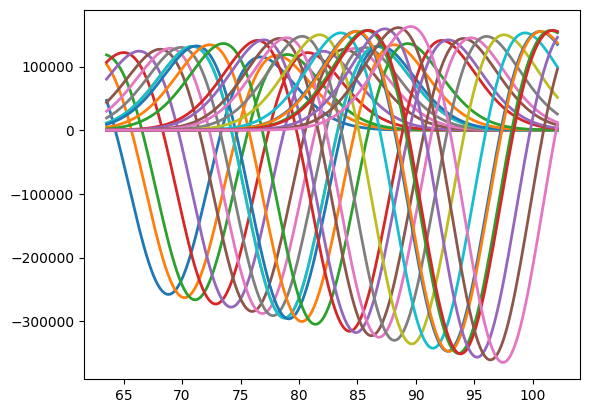

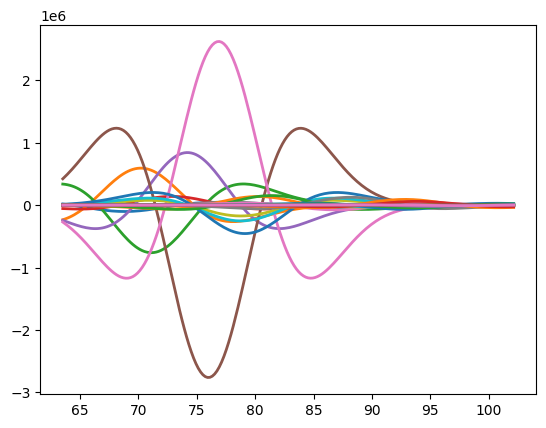

(-1000.0, 2500.0)

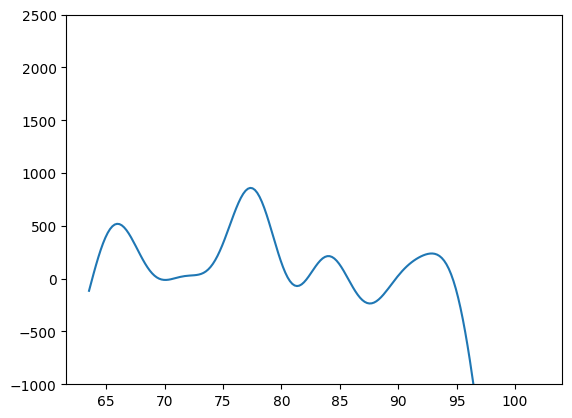

In [ ]:
individual_samples = barrier_from_sigma_samples(E_pred, contrib.T)

for i in range(contrib.shape[1]):
    plt.plot(E_pred, individual_samples[i]/gp.alpha_[i], lw=2)
plt.show()

for i in range(contrib.shape[1]):
    plt.plot(E_pred, individual_samples[i], lw=2)
plt.show()

barrier = np.sum(individual_samples, axis=0)
plt.plot(E_pred, barrier)
plt.ylim(-1000, 2500)